# Decoding Visual Object Categories from fMRI: Logistic Regression

**Question:** Can we tell which object category a person was viewing from activity in their ventral temporal cortex?

**Data:** Haxby et al. (2001), subject 1 (via `nilearn`). 12 runs, 8 object categories plus rest.

**Model:** L2-regularized multinomial logistic regression, evaluated with leave-one-run-out cross-validation, a majority-class baseline, and a permutation test. A linear SVM is run alongside for comparison.

**Plots:** per-run accuracy, confusion matrices (counts and normalized), per-class F1, permutation null, accuracy vs. regularization, and voxel weight maps shown several ways (z-slice grid, orthogonal views, mosaic, preferred-category map, weight heatmap, and map correlations).

## 1. Setup

In [116]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

from nilearn import datasets, plotting
from nilearn.maskers import NiftiMasker

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import (
    LeaveOneGroupOut, cross_val_score, cross_val_predict, permutation_test_score
)
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

# --- Settings ---
C = 1.0                  # inverse regularization strength (smaller = stronger)
MAX_ITER = 1000
RANDOM_STATE = 0
RUN_PERMUTATION_TEST = True
N_PERMUTATIONS = 999     # p-value floor = 1/(N+1). Logistic regression is slow: lower this first if needed
N_JOBS = 2               # -1 can hang in notebooks with limited memory/cores

## 2. Load data and labels

In [117]:
dataset = datasets.fetch_haxby()
func_filename = dataset.func[0]

labels = pd.read_csv(dataset.session_target[0], sep=" ")
conditions_all = labels["labels"]
runs_all = labels["chunks"]

print("Timepoints:", len(labels))
print(conditions_all.value_counts())

[fetch_haxby] Dataset directory found: /Users/sonakshisharma/nilearn_data/haxby2001
Timepoints: 1452
labels
rest            588
scissors        108
face            108
cat             108
shoe            108
house           108
scrambledpix    108
bottle          108
chair           108
Name: count, dtype: int64


## 3. Ventral temporal cortex activity

The scan is masked and detrended on the full time series, and rest rows are removed afterwards.

In [118]:
masker_vt = NiftiMasker(
    mask_img=dataset.mask_vt[0],
    smoothing_fwhm=8,
    standardize="zscore_sample",
    memory="nilearn_cache",
    memory_level=1,
    mask_strategy="epi",
    verbose=1,
)
X_all = masker_vt.fit_transform(func_filename)
print("Full matrix (timepoints x voxels):", X_all.shape)

[NiftiMasker.wrapped] Loading data from .../subj2/bold.nii.gz
[NiftiMasker.wrapped] Loading mask from .../mask4_vt.nii.gz
[NiftiMasker.wrapped] Resampling mask
[NiftiMasker.wrapped] Finished fit
Full matrix (timepoints x voxels): (1452, 464)


## 4. Keep object categories only

Removing rest leaves 8 balanced classes (108 rows each), so chance is 1/8 = 12.5%. The originals keep their names; filtered versions get new ones.

In [119]:
keep = (conditions_all != "rest").values

X = X_all[keep]
y = conditions_all[keep].values
groups = runs_all[keep].values

print("X:", X.shape, "| y:", y.shape, "| groups:", groups.shape)
print(pd.Series(y).value_counts())

assert X.shape[0] == len(y) == len(groups) == 864
assert len(np.unique(y)) == 8

X: (864, 464) | y: (864,) | groups: (864,)
scissors        108
face            108
cat             108
shoe            108
house           108
scrambledpix    108
bottle          108
chair           108
Name: count, dtype: int64


## 5. Cross-validated accuracy (leave-one-run-out)

In [120]:
cv = LeaveOneGroupOut()
run_ids = np.unique(groups)

lr = LogisticRegression(C=C, max_iter=MAX_ITER)
lr_scores = cross_val_score(lr, X, y, groups=groups, cv=cv)

svm_scores = cross_val_score(SVC(kernel="linear"), X, y, groups=groups, cv=cv)
dummy_scores = cross_val_score(DummyClassifier(strategy="most_frequent"), X, y, groups=groups, cv=cv)

print(f"Logistic regression: {lr_scores.mean():.3f} +/- {lr_scores.std():.3f}")
print(f"Linear SVM         : {svm_scores.mean():.3f} +/- {svm_scores.std():.3f}")
print(f"Dummy baseline     : {dummy_scores.mean():.3f} +/- {dummy_scores.std():.3f}")
print(f"Theoretical chance : {1/8:.3f}")

Logistic regression: 0.733 +/- 0.082
Linear SVM         : 0.646 +/- 0.089
Dummy baseline     : 0.125 +/- 0.000
Theoretical chance : 0.125


### Plot 1: accuracy per held-out run (logistic regression vs. SVM vs. chance)

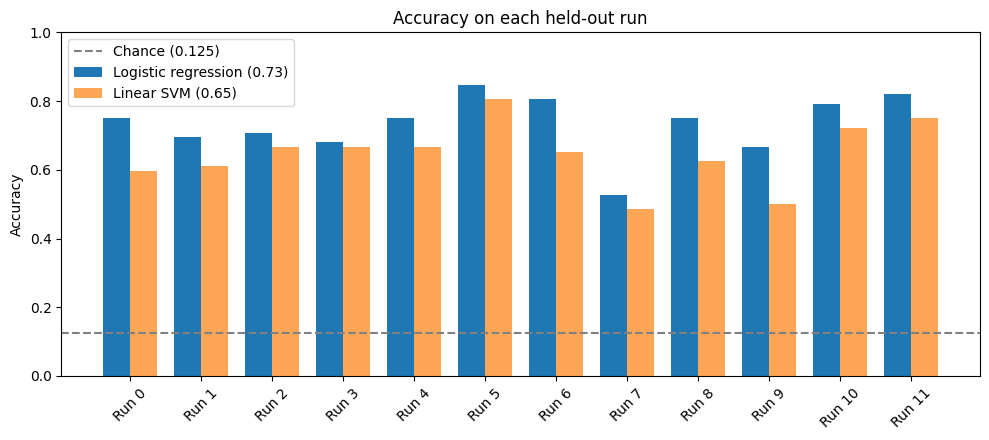

In [121]:
x = np.arange(len(run_ids))
w = 0.38

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(x - w/2, lr_scores, w, label=f"Logistic regression ({lr_scores.mean():.2f})")
ax.bar(x + w/2, svm_scores, w, label=f"Linear SVM ({svm_scores.mean():.2f})", alpha=0.7)
ax.axhline(1/8, color="gray", linestyle="--", label="Chance (0.125)")
ax.set_xticks(x); ax.set_xticklabels([f"Run {r}" for r in run_ids], rotation=45)
ax.set_ylabel("Accuracy"); ax.set_ylim(0, 1)
ax.set_title("Accuracy on each held-out run")
ax.legend()
plt.tight_layout()
plt.savefig("lr_accuracy_per_run.png", dpi=200)
plt.show()

## 6. Where does the model make mistakes?

In [122]:
y_pred = cross_val_predict(LogisticRegression(C=C, max_iter=MAX_ITER), X, y, groups=groups, cv=cv)
print(classification_report(y, y_pred))

              precision    recall  f1-score   support

      bottle       0.47      0.66      0.55       108
         cat       0.79      0.77      0.78       108
       chair       0.71      0.60      0.65       108
        face       0.84      0.80      0.82       108
       house       0.92      0.92      0.92       108
    scissors       0.62      0.56      0.59       108
scrambledpix       0.97      0.90      0.93       108
        shoe       0.65      0.67      0.66       108

    accuracy                           0.73       864
   macro avg       0.75      0.73      0.74       864
weighted avg       0.75      0.73      0.74       864



### Plot 2: confusion matrix (raw counts and row-normalized, side by side)

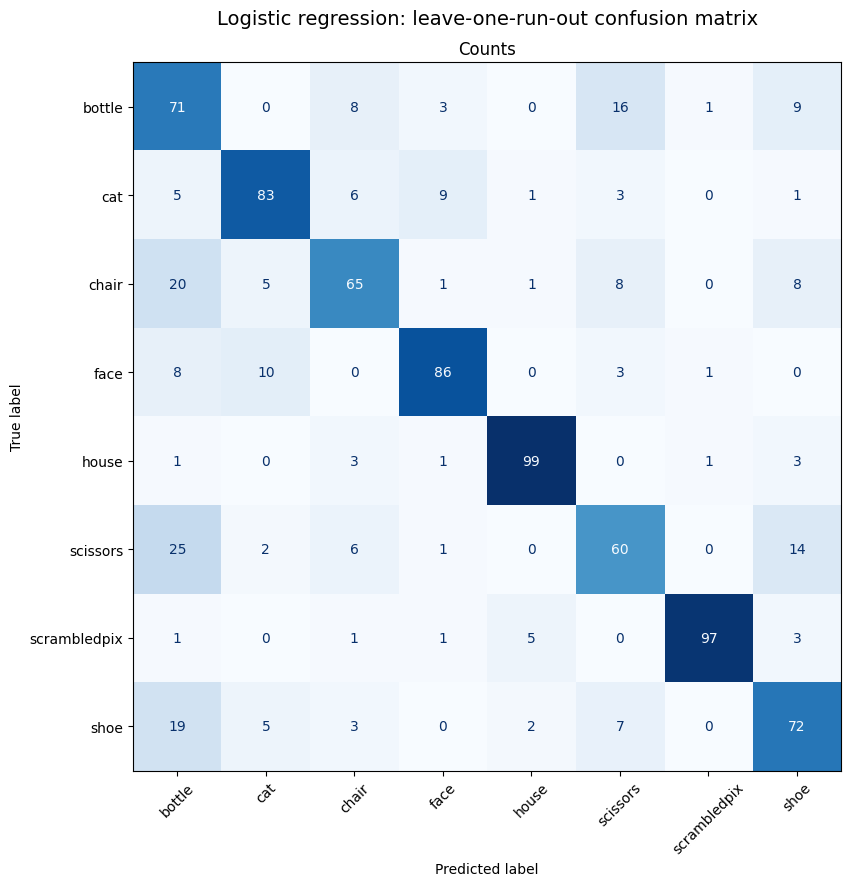

In [123]:
fig, axes = plt.subplots(1, figsize=(20, 9))
ConfusionMatrixDisplay.from_predictions(
    y, y_pred, values_format="d", xticks_rotation=45, cmap="Blues", ax=axes, colorbar=False
)
axes.set_title("Counts")
plt.suptitle("Logistic regression: leave-one-run-out confusion matrix", fontsize=14)
plt.tight_layout()
plt.savefig("lr_confusion_matrix.png", dpi=200)
plt.show()

### Plot 3: per-class F1 score

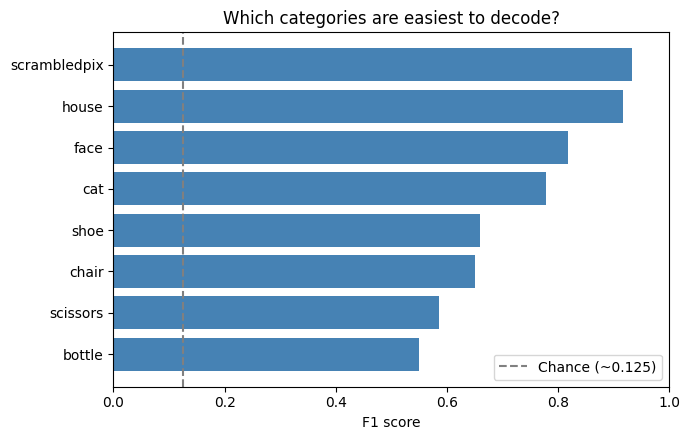

In [124]:
report = classification_report(y, y_pred, output_dict=True)
classes = sorted(np.unique(y))
f1 = pd.Series({c: report[c]["f1-score"] for c in classes}).sort_values()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(f1.index, f1.values, color="steelblue")
ax.axvline(1/8, color="gray", linestyle="--", label="Chance (~0.125)")
ax.set_xlabel("F1 score"); ax.set_xlim(0, 1)
ax.set_title("Which categories are easiest to decode?")
ax.legend()
plt.tight_layout()
plt.savefig("lr_f1_per_class.png", dpi=200)
plt.show()

### Plot 4: accuracy vs. regularization strength

This is for understanding only. Choosing `C` with the same cross-validation you report would be slightly optimistic, so keep the headline number from the fixed `C` above.

C=0.0001   accuracy=0.318 +/- 0.102
C=0.001    accuracy=0.481 +/- 0.090
C=0.01     accuracy=0.657 +/- 0.092
C=0.1      accuracy=0.736 +/- 0.082
C=1        accuracy=0.733 +/- 0.082
C=10       accuracy=0.716 +/- 0.081


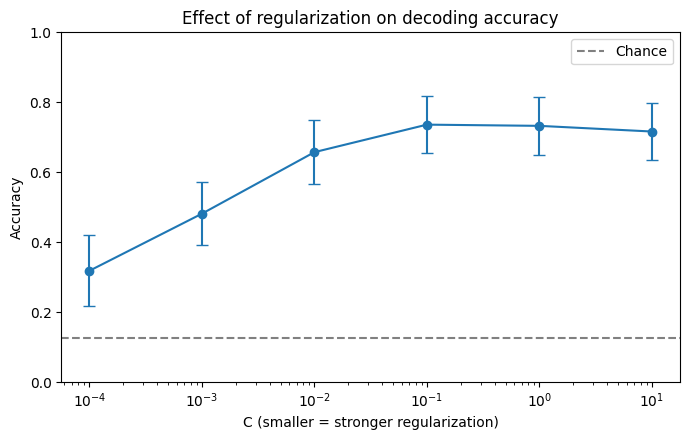

In [125]:
C_values = [0.0001, 0.001, 0.01, 0.1, 1, 10]
means, stds = [], []
for c in C_values:
    s = cross_val_score(LogisticRegression(C=c, max_iter=MAX_ITER), X, y, groups=groups, cv=cv)
    means.append(s.mean()); stds.append(s.std())
    print(f"C={c:<8} accuracy={s.mean():.3f} +/- {s.std():.3f}")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.errorbar(C_values, means, yerr=stds, marker="o", capsize=4)
ax.axhline(1/8, color="gray", linestyle="--", label="Chance")
ax.set_xscale("log")
ax.set_xlabel("C (smaller = stronger regularization)"); ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1); ax.legend()
ax.set_title("Effect of regularization on decoding accuracy")
plt.tight_layout()
plt.savefig("lr_accuracy_vs_C.png", dpi=200)
plt.show()

## 7. Permutation test

Labels are shuffled and the whole cross-validation is repeated. Logistic regression is the slow part here, so reduce `N_PERMUTATIONS` if it takes too long. The p-value floor is `1/(N+1)`.

In [126]:
if RUN_PERMUTATION_TEST:
    score, perm_scores, pvalue = permutation_test_score(
        LogisticRegression(C=C, max_iter=MAX_ITER), X, y,
        groups=groups, cv=cv,
        n_permutations=N_PERMUTATIONS, n_jobs=N_JOBS, random_state=RANDOM_STATE,
    )
    print(f"Score: {score:.3f} | null: {perm_scores.mean():.3f} +/- {perm_scores.std():.3f} | p = {pvalue:.4f}")
else:
    score, perm_scores, pvalue = lr_scores.mean(), np.array([np.nan]), np.nan

Python(46380) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(46381) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


Score: 0.733 | null: 0.126 +/- 0.011 | p = 0.0010


### Plot 5: real score vs. permutation null

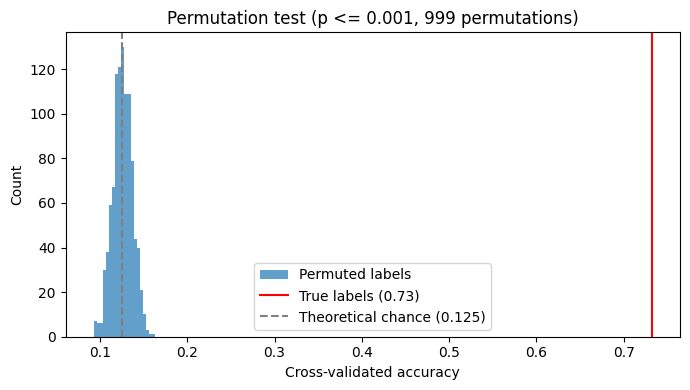

In [127]:
if RUN_PERMUTATION_TEST:
    plt.figure(figsize=(7, 4))
    plt.hist(perm_scores, bins=20, alpha=0.7, label="Permuted labels")
    plt.axvline(score, color="red", label=f"True labels ({score:.2f})")
    plt.axvline(1/8, color="gray", linestyle="--", label="Theoretical chance (0.125)")
    plt.xlabel("Cross-validated accuracy"); plt.ylabel("Count"); plt.legend()
    plt.title(f"Permutation test (p <= {pvalue:.3f}, {N_PERMUTATIONS} permutations)")
    plt.tight_layout()
    plt.savefig("lr_permutation_test.png", dpi=200)
    plt.show()

## 8. Voxel weight maps

The model is fit once on all object data, giving one weight vector per category (`coef_` has shape `(8, n_voxels)`). Logistic regression here is **multinomial**: all categories are fit jointly with a softmax, so each map says how strongly a voxel pushes the prediction toward that category *relative to the others*. These maps show where the decoder looks, not how well it generalizes.

In [128]:
lr_full = LogisticRegression(C=C, max_iter=MAX_ITER).fit(X, y)
weights = lr_full.coef_                       # (8, n_voxels)
classes = lr_full.classes_
print(weights.shape, classes)

assert weights.shape[1] == masker_vt.n_elements_   # masker must match the data

# Shared settings so panels are comparable
z_cut = plotting.find_xyz_cut_coords(dataset.mask_vt[0])[2]
vmax = np.abs(weights).max()
thr = {c: np.percentile(np.abs(weights[i]), 95) for i, c in enumerate(classes)}
weight_imgs = {c: masker_vt.inverse_transform(weights[i]) for i, c in enumerate(classes)}

(8, 464) ['bottle' 'cat' 'chair' 'face' 'house' 'scissors' 'scrambledpix' 'shoe']


/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_23624/2498173864.py:9: UserWarning: Could not determine cut coords: All voxels were masked by the thresholding. Returning the center of mass instead.
  z_cut = plotting.find_xyz_cut_coords(dataset.mask_vt[0])[2]


[NiftiMasker.inverse_transform] Computing image from signals
[NiftiMasker.inverse_transform] Computing image from signals
[NiftiMasker.inverse_transform] Computing image from signals
[NiftiMasker.inverse_transform] Computing image from signals
[NiftiMasker.inverse_transform] Computing image from signals
[NiftiMasker.inverse_transform] Computing image from signals
[NiftiMasker.inverse_transform] Computing image from signals
[NiftiMasker.inverse_transform] Computing image from signals


### Plot 6: z-slice grid, one panel per category (same slice and color scale)

/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_23624/2374642079.py:8: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


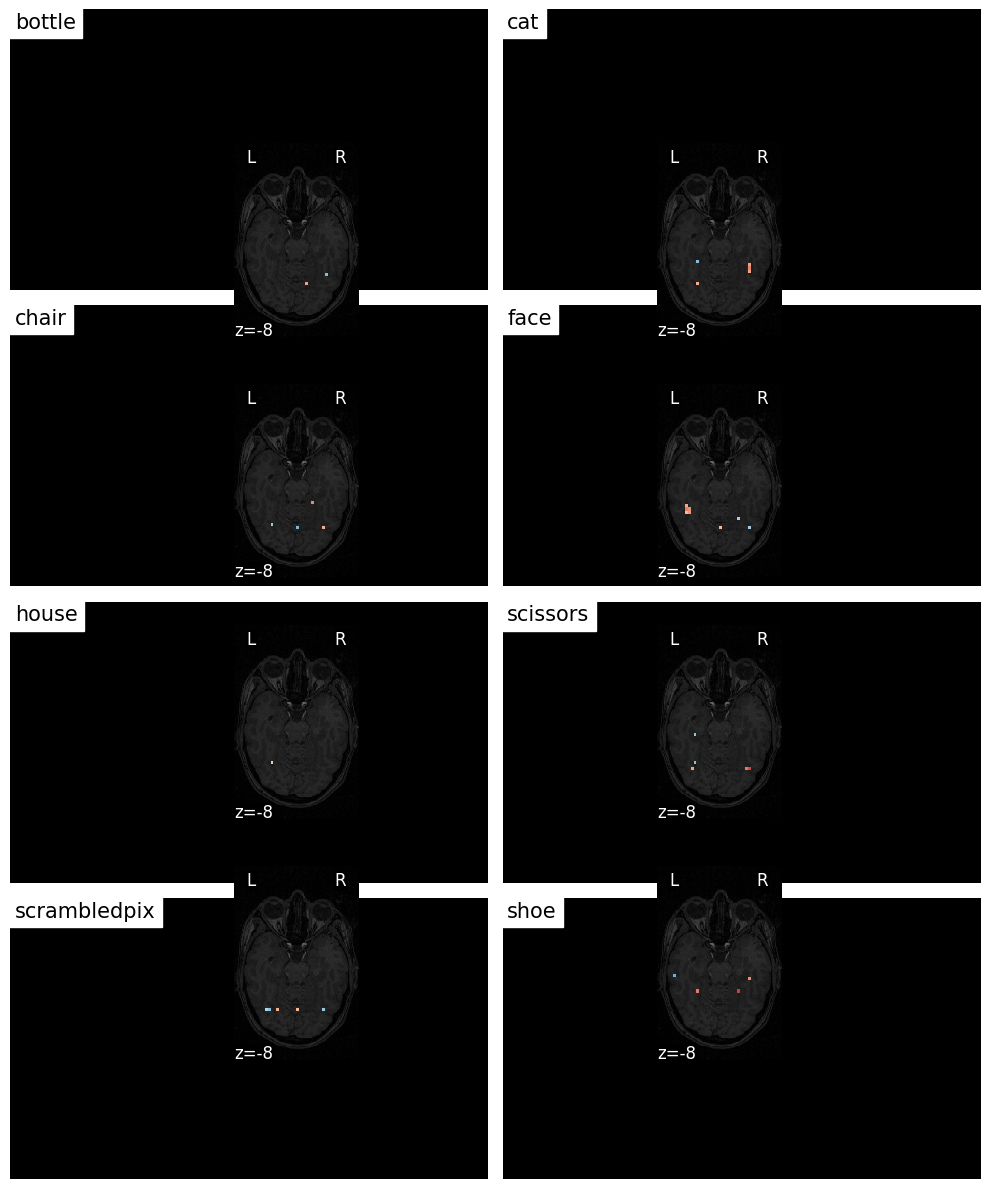

In [129]:
fig, axes = plt.subplots(4, 2, figsize=(10, 12))
for ax, c in zip(axes.ravel(), classes):
    plotting.plot_stat_map(
        weight_imgs[c], bg_img=dataset.anat[0],
        title=c, display_mode="z", cut_coords=[z_cut],
        threshold=thr[c], vmax=vmax, axes=ax, colorbar=False,
    )
plt.tight_layout()
plt.savefig("lr_weights_grid.png", dpi=150)
plt.show()

### Plot 7: orthogonal views (sagittal / coronal / axial) for face and house

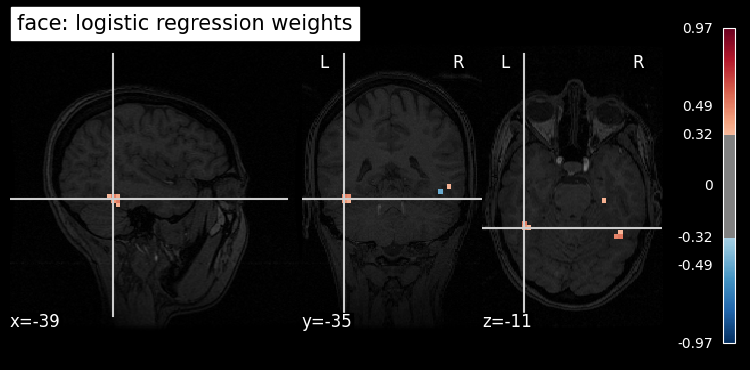

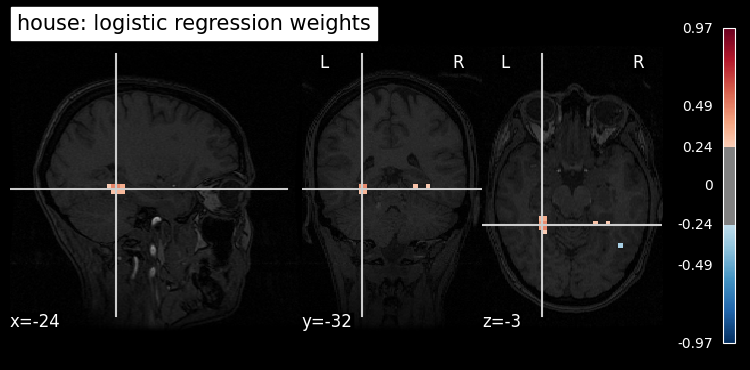

In [130]:
for c in ["face", "house"]:
    plotting.plot_stat_map(
        weight_imgs[c], bg_img=dataset.anat[0],
        title=f"{c}: logistic regression weights",
        display_mode="ortho", threshold=thr[c], vmax=vmax,
        output_file=f"lr_weights_ortho_{c}.png",
    )
    plotting.show()

### Plot 8: mosaic of many slices for one category

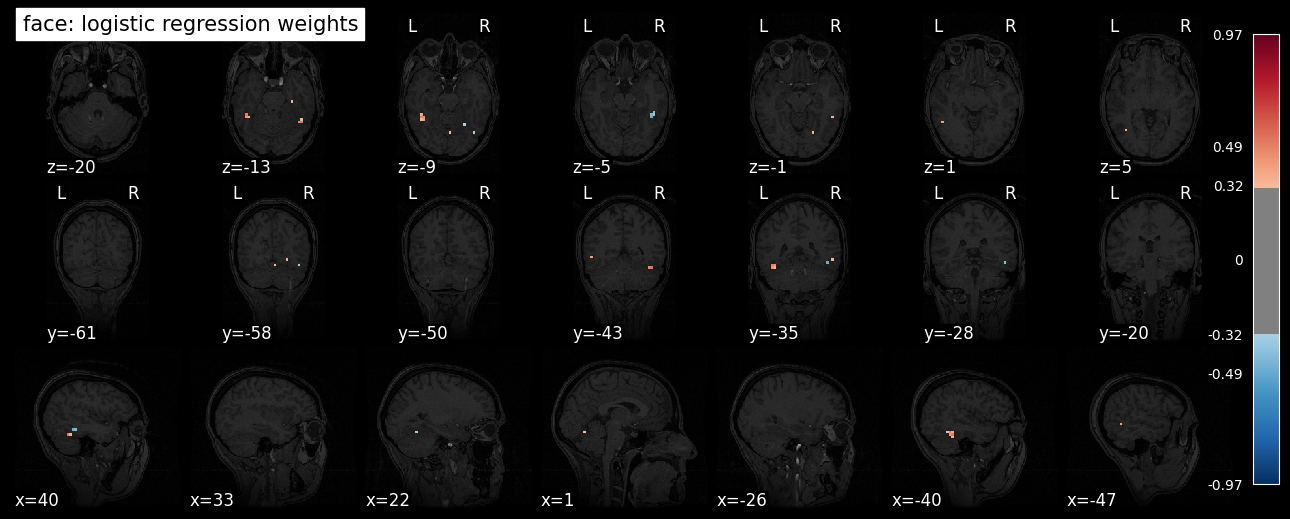

In [131]:
plotting.plot_stat_map(
    weight_imgs["face"], bg_img=dataset.anat[0],
    title="face: logistic regression weights",
    display_mode="mosaic", threshold=thr["face"], vmax=vmax,
    output_file="lr_weights_mosaic_face.png",
)
plotting.show()

### Plot 9: preferred-category map

Each voxel is colored by the category whose weight is largest there. Only voxels in the top 10% of that maximum weight are shown.

[NiftiMasker.inverse_transform] Computing image from signals


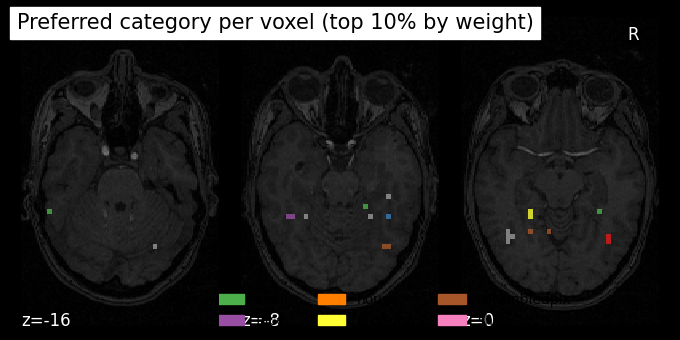

In [132]:
winner = weights.argmax(axis=0) + 1                  # 1..8
strength = weights.max(axis=0)
winner_shown = np.where(strength >= np.percentile(strength, 90), winner, 0)

winner_img = masker_vt.inverse_transform(winner_shown.astype(float))
cmap = plt.get_cmap("Set1")
colors = [cmap(i) for i in range(len(classes))]

display = plotting.plot_roi(
    winner_img, bg_img=dataset.anat[0],
    display_mode="z", cut_coords=[z_cut - 8, z_cut, z_cut + 8],
    cmap="Set1", vmin=0.5, vmax=len(classes) + 0.5, alpha=0.8, colorbar=False,
    title="Preferred category per voxel (top 10% by weight)",
)
plt.gcf().legend(
    handles=[Patch(color=colors[i], label=classes[i]) for i in range(len(classes))],
    loc="lower center", ncol=4, frameon=False,
)
plt.savefig("lr_weights_preferred_category.png", dpi=150, bbox_inches="tight")
plt.show()

### Plot 10: heatmap of weights (categories x most informative voxels)

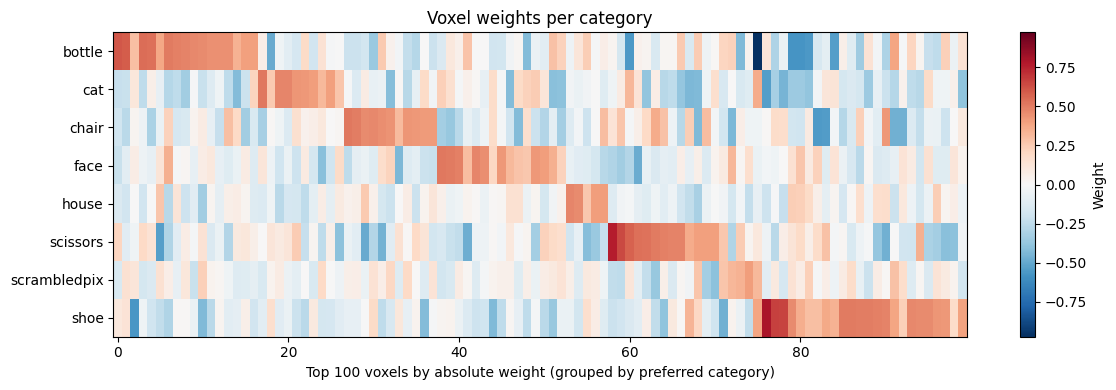

In [133]:
top_idx = np.argsort(np.abs(weights).max(axis=0))[::-1][:100]
order = np.lexsort((-np.abs(weights[:, top_idx]).max(axis=0), weights[:, top_idx].argmax(axis=0)))
heat = weights[:, top_idx][:, order]

fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(heat, aspect="auto", cmap="RdBu_r", vmin=-np.abs(heat).max(), vmax=np.abs(heat).max())
ax.set_yticks(range(len(classes))); ax.set_yticklabels(classes)
ax.set_xlabel("Top 100 voxels by absolute weight (grouped by preferred category)")
ax.set_title("Voxel weights per category")
plt.colorbar(im, ax=ax, label="Weight")
plt.tight_layout()
plt.savefig("lr_weights_heatmap.png", dpi=200)
plt.show()

### Plot 11: how similar are the category weight maps?

Categories whose weight maps correlate (or whose decodings are confused in the confusion matrix) are likely to share a similar spatial code.

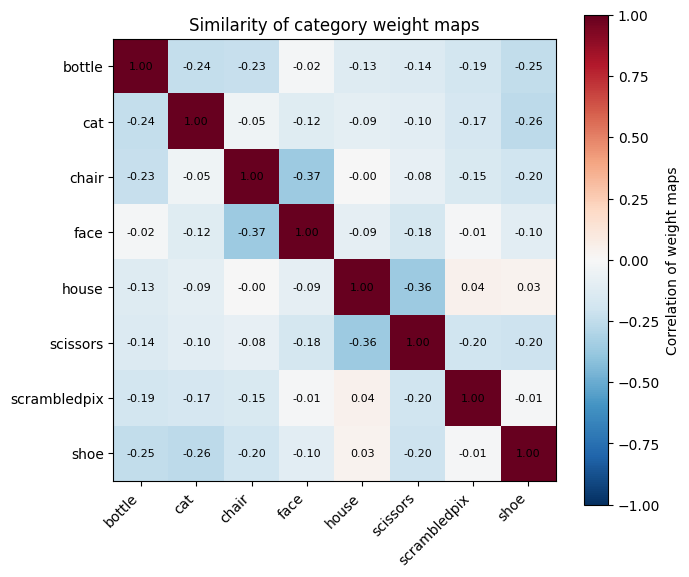

In [134]:
corr = np.corrcoef(weights)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(classes))); ax.set_xticklabels(classes, rotation=45, ha="right")
ax.set_yticks(range(len(classes))); ax.set_yticklabels(classes)
for i in range(len(classes)):
    for j in range(len(classes)):
        ax.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, ax=ax, label="Correlation of weight maps")
ax.set_title("Similarity of category weight maps")
plt.tight_layout()
plt.savefig("lr_weights_correlation.png", dpi=200)
plt.show()

### Plot 12: distribution of voxel weights

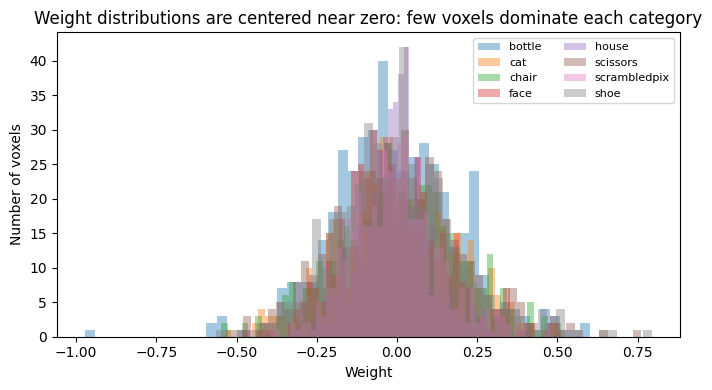

In [135]:
fig, ax = plt.subplots(figsize=(7, 4))
for i, c in enumerate(classes):
    ax.hist(weights[i], bins=50, alpha=0.4, label=c)
ax.set_xlabel("Weight"); ax.set_ylabel("Number of voxels")
ax.set_title("Weight distributions are centered near zero: few voxels dominate each category")
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.savefig("lr_weights_distribution.png", dpi=200)
plt.show()

## 9. Summary

In [136]:
summary = (
    f"{lr_scores.mean()*100:.1f}% +/- {lr_scores.std()*100:.1f}% 8-class accuracy "
    f"(logistic regression, C={C}, leave-one-run-out CV, single subject); "
    f"linear SVM {svm_scores.mean()*100:.1f}%; chance 12.5%, dummy baseline {dummy_scores.mean()*100:.1f}%."
)
if RUN_PERMUTATION_TEST:
    summary += (
        f" Permutation null {perm_scores.mean()*100:.1f}% +/- {perm_scores.std()*100:.1f}%, "
        f"p <= {pvalue:.3f} ({N_PERMUTATIONS} permutations)."
    )
print(summary)

73.3% +/- 8.2% 8-class accuracy (logistic regression, C=1.0, leave-one-run-out CV, single subject); linear SVM 64.6%; chance 12.5%, dummy baseline 12.5%. Permutation null 12.6% +/- 1.1%, p <= 0.001 (999 permutations).


## Conclusions and limitations

- Object category can be decoded from ventral temporal cortex activity well above chance with a linear classifier, using held-out runs.
- Logistic regression and the linear SVM perform similarly, which suggests the limit is signal-to-noise in the data, not the model.
- The confusion matrix, F1 plot, and weight-map correlations point to the same categories sharing similar patterns.

**Limitations**
- One subject only.
- Decoding shows information is present in the activity, not how the brain uses it.
- Weight maps come from a model fit on all data and show where the decoder looks, not a precise map of category selectivity.
- The data are in subject space, so slice coordinates are not MNI coordinates.
- Permutation p-value is limited by the number of permutations.